# Online vásárlási szándék – klasszifikáció

**Kérdés és célváltozó.** A cél annak becslése, hogy egy webáruházi munkamenet végén történt-e vásárlás (`Revenue=True`, pozitív osztály). Az álriasztás egy felesleges marketinges megkeresés vagy kedvezmény költsége; a kihagyott pozitív egy elmaradt konverziós lehetőség. A fájl nem tartalmaz pénzügyi költségadatot, ezért a küszöböt nem üzleti profitból optimalizálom: PR-AUC-ot és kiegyensúlyozott pontosságot használok, és külön megmutatom a legmagasabb becsült kockázatú 10% vásárlási találati arányát.

A notebook a `Homework 4/sources/archive/online_shoppers_intention.csv` adatot használja. Az EDA leíró jellegű; minden tanulható előfeldolgozás és modellillesztés a zárolt, rétegzett train/holdout split után, pipeline-ban történik. Az ismétlődő bemeneti sorokat közös csoportban tartom, hogy ne kerüljenek külön foldba.

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    precision_recall_curve,
    roc_curve,
)
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

SEED = 42
DATA_NAME = "online_shoppers_intention.csv"

def find_data_file():
    for base in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
        options = (
            base / "sources" / "archive" / DATA_NAME,
            base / "Homework 4" / "sources" / "archive" / DATA_NAME,
        )
        for option in options:
            if option.is_file():
                return option
    raise FileNotFoundError(f"Nem találom az adatfájlt ({DATA_NAME}); ellenőrizd a sources/archive mappát.")

DATA_PATH = find_data_file()
HOMEWORK_DIR = DATA_PATH.parents[2]
df = pd.read_csv(DATA_PATH)
TARGET = "Revenue"
if TARGET not in df:
    raise ValueError(f"Hiányzik a célváltozó: {TARGET}")
y = df[TARGET].astype(int)
print(f"Fájl: {DATA_PATH}")
print(f"Méret: {df.shape[0]:,} sor × {df.shape[1]} oszlop")
print(f"Pozitív (vásárló) osztály: {y.sum():,}/{len(y):,} = {y.mean():.2%}")

Fájl: /workspaces/Data-Science-Course/Homework 4/sources/archive/online_shoppers_intention.csv
Méret: 12,330 sor × 18 oszlop
Pozitív (vásárló) osztály: 1,908/12,330 = 15.47%


## EDA és adatminőség

A vásárlási arányt a teljes, címkézett archívumon mérem és jelentem. A diagramok az osztályegyensúlyt, illetve a hónaponkénti mintaszámot és vásárlási arányt mutatják; ez utóbbi szezonális eltérésekre utalhat, de nincs dátum/időbélyeg, amellyel időbeli validációt lehetne szabályosan végezni.

Hiányzó értékek oszloponként:


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
missing_count,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


Teljes sor szerinti ismétlődés (felesleges példányok): 125
Többször szereplő, modellben használt prediktorsorok: 201
Eltérő célértékű, azonos prediktorcsoportok: 0
A Revenue arány: 
Revenue
Nem vásárolt    10422
Vásárolt         1908
Name: count, dtype: int64


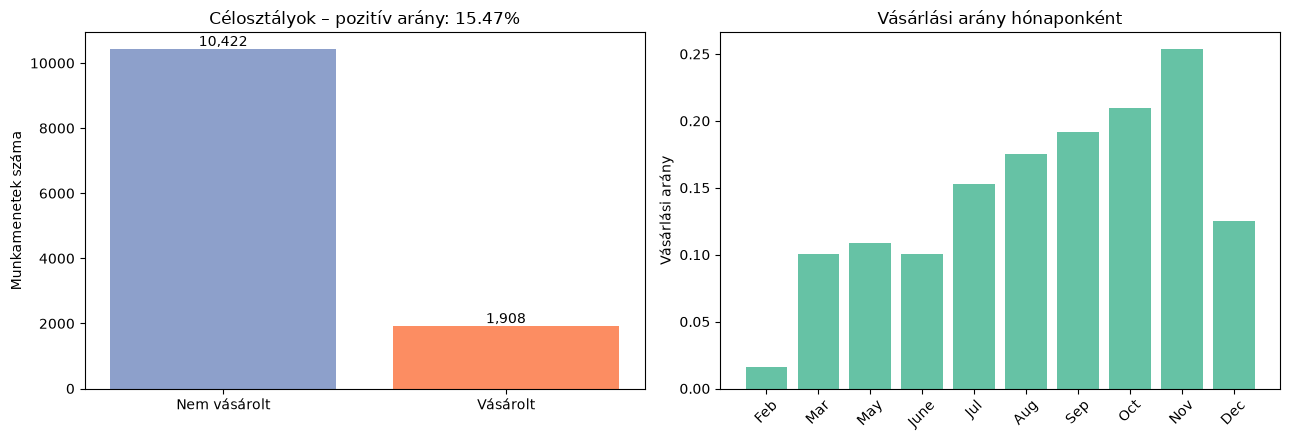

,sessions,purchase_rate
Month,,
Feb,184,1.6%
Mar,1907,10.1%
May,3364,10.9%
June,288,10.1%
Jul,432,15.3%
Aug,433,17.6%
Sep,448,19.2%
Oct,549,20.9%
Nov,2998,25.4%


In [2]:
positive_rate = float(df[TARGET].mean())
missing = df.isna().sum().sort_values(ascending=False)
exact_duplicate_rows = int(df.duplicated().sum())
audit_X = df.drop(columns=[TARGET, "PageValues"])
audit_groups = pd.util.hash_pandas_object(audit_X, index=False)
repeated_predictor_rows = int(audit_groups.duplicated(keep=False).sum())
conflicting_duplicate_groups = int(df.groupby(audit_groups, sort=False)[TARGET].nunique().gt(1).sum())

print("Hiányzó értékek oszloponként:")
display(missing.to_frame("missing_count").T)
print(f"Teljes sor szerinti ismétlődés (felesleges példányok): {exact_duplicate_rows}")
print(f"Többször szereplő, modellben használt prediktorsorok: {repeated_predictor_rows}")
print(f"Eltérő célértékű, azonos prediktorcsoportok: {conflicting_duplicate_groups}")
print("A Revenue arány: ")
print(df[TARGET].value_counts().rename(index={False: "Nem vásárolt", True: "Vásárolt"}))

month_stats = df.groupby("Month", observed=True)[TARGET].agg(sessions="size", purchase_rate="mean")
month_order = [m for m in ["Feb", "Mar", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"] if m in month_stats.index]
month_stats = month_stats.reindex(month_order)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
counts = df[TARGET].value_counts().reindex([False, True])
axes[0].bar(["Nem vásárolt", "Vásárolt"], counts.values, color=["#8da0cb", "#fc8d62"])
axes[0].set_title(f"Célosztályok – pozitív arány: {positive_rate:.2%}")
axes[0].set_ylabel("Munkamenetek száma")
for i, value in enumerate(counts.values):
    axes[0].text(i, value, f"{value:,}", ha="center", va="bottom")
axes[1].bar(month_stats.index, month_stats["purchase_rate"], color="#66c2a5")
axes[1].set_title("Vásárlási arány hónaponként")
axes[1].set_ylabel("Vásárlási arány")
axes[1].tick_params(axis="x", rotation=45)
fig.tight_layout()
plt.show()

display(month_stats.assign(purchase_rate=lambda x: x.purchase_rate.map(lambda v: f"{v:.1%}")))

### Tisztítási döntések és szivárgás

- A hiányzási arányt minden oszlopra ellenőriztem. Ha nincs hiány, a hiányzás nem hordoz itt megfigyelhető jelet; hiányzásjelzőt nem gyártok. A pipeline medián/módusz imputálói csak jövőbeli, esetleg hiányos bemenet esetére vannak benne, és kizárólag az adott tanító foldon illeszkednek.
- A nulla oldalszám/időtartam/ráták hihető „nem történt ilyen aktivitás” értékek, nem hiányzások. A kódolt operációs rendszer, böngésző, régió és forgalomtípus kategóriák, ezért one-hot kódolást kapnak, nem hamis sorrendet.
- A 125 teljesen ismétlődő sor megfigyelési azonosságot nem bizonyít (lehet két egyforma munkamenet), ezért nem törlöm őket. Az azonos prediktorértékű sorok csoportazonosítót kapnak, így nem szivároghatnak át a train/holdout határon vagy a CV-foldok között. Azonos prediktor-csoportok között nem találtam eltérő címkét.
- A `PageValues` oszlopot kizárom: a tranzakcióhoz kapcsolódó, vásárlás utáni információt is tükrözheti, tehát a modell használatakor célérték-szivárgás kockázata van. A többi változót a munkamenet viselkedéseként kezelem, bár adatszótár és tényleges bevezetési időpont nélkül azok időbeli elérhetőségét sem lehet teljes bizonyossággal ellenőrizni.

**Hiányzás vagy szivárgás?** Nincs hiányzó érték, így a hiányzás jel-/szivárgás-mechanizmusára ebből az archívumból nem lehet következtetni. Ha új adatnál hiány jelenik meg, először az adatgyűjtési folyamatot kell megvizsgálni: a mező hiánya lehet hasznos folyamatjel, de lehet olyan későbbi esemény következménye is, amelyet előrejelzéskor nem szabad ismerni.

## Zárolt split – minden modell előtt

A rekordok nem időbélyegzett munkamenetek; ezért a stratifikált véletlen split a célosztály arányát tartja közel azonosan. Az egyedi bemeneti sorokat csoportként kezelő `StratifiedGroupKFold` ötödikének első foldja a zárolt teszthalmaz (kb. 20%), fix `seed=42` mellett. A tesztcímkét a legvégső értékelésig nem használom modell- vagy küszöbválasztásra.

In [3]:
# PageValues kizárása a prediktorok közül a lehetséges célérték-szivárgás miatt.
X_all = df.drop(columns=[TARGET, "PageValues"]).copy()
y_all = df[TARGET].astype(int).copy()
# Hash csak a csoportosításhoz; nem kerül a modellbe.
groups_all = pd.util.hash_pandas_object(X_all, index=False).to_numpy()

holdout_splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(holdout_splitter.split(X_all, y_all, groups_all))
X_train, X_test = X_all.iloc[train_idx].copy(), X_all.iloc[test_idx].copy()
y_train, y_test = y_all.iloc[train_idx].copy(), y_all.iloc[test_idx].copy()
groups_train = groups_all[train_idx]

cv_splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_splits = list(cv_splitter.split(X_train, y_train, groups_train))
print(f"Train: {len(X_train):,} ({y_train.mean():.2%} pozitív); zárolt teszt: {len(X_test):,} ({y_test.mean():.2%} pozitív)")
print(f"Train-foldok: {[len(valid) for _, valid in cv_splits]}")
print(f"Train csoportok: {pd.Series(groups_train).nunique():,}; teszt csoportok: {pd.Series(groups_all[test_idx]).nunique():,}")

Train: 9,864 (15.48% pozitív); zárolt teszt: 2,466 (15.45% pozitív)
Train-foldok: [1973, 1973, 1973, 1973, 1972]
Train csoportok: 9,766; teszt csoportok: 2,439


## Előfeldolgozás és alapmodellek

A numerikus oszlopok medián imputálása és standardizálása, illetve a kategóriák módusz imputálása és one-hot kódolása egyetlen `Pipeline`/`ColumnTransformer` része, ezért minden fold csak a saját tanító részéből tanulja ezeket. Azonos öt foldon hasonlítom össze a dummy, logisztikus regresszió, döntési fa, random forest és XGBoost modelleket. A fő rangsorolási mutató az átlagos precision-recall görbe alatti terület (PR-AUC); az alap 0,5-ös küszöb melletti kiegyensúlyozott pontosság kiegészítő. A nyers accuracy félrevezető lenne, mert a „mindig nem vásárol” modell is kb. 84,5%-ot érne el.

In [4]:
CATEGORICAL = ["Month", "OperatingSystems", "Browser", "Region", "TrafficType", "VisitorType", "Weekend"]
NUMERIC = [column for column in X_train.columns if column not in CATEGORICAL]

def make_preprocessor(numeric_columns=NUMERIC):
    return ColumnTransformer(
        transformers=[
            ("num", Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler()),
            ]), numeric_columns),
            ("cat", Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore")),
            ]), CATEGORICAL),
        ],
        remainder="drop",
    )

def make_pipeline(model, numeric_columns=NUMERIC):
    return Pipeline([
        ("preprocess", make_preprocessor(numeric_columns)),
        ("model", model),
    ])

models = {
    "Dummy": DummyClassifier(strategy="prior"),
    "Logistic regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED),
    "Decision tree": DecisionTreeClassifier(max_depth=6, min_samples_leaf=20, class_weight="balanced", random_state=SEED),
    "Random forest": RandomForestClassifier(n_estimators=250, min_samples_leaf=5, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED),
    "XGBoost": XGBClassifier(n_estimators=250, max_depth=4, learning_rate=0.05, subsample=0.9, colsample_bytree=0.9, reg_lambda=2, eval_metric="logloss", tree_method="hist", n_jobs=1, random_state=SEED),
}

def top_decile_precision(y_true, probabilities):
    if np.ptp(probabilities) < 1e-12:
        return np.nan  # állandó dummy pontszám nem rangsorol
    n_top = max(1, int(np.ceil(0.10 * len(probabilities))))
    top = np.argsort(-probabilities, kind="stable")[:n_top]
    return float(np.asarray(y_true)[top].mean())

def evaluate_cv(estimator, X, y, splits):
    oof = np.full(len(y), np.nan, dtype=float)
    fold_rows = []
    for fold_number, (fit_idx, valid_idx) in enumerate(splits, start=1):
        fitted = clone(estimator)
        fitted.fit(X.iloc[fit_idx], y.iloc[fit_idx])
        probabilities = fitted.predict_proba(X.iloc[valid_idx])[:, 1]
        oof[valid_idx] = probabilities
        truth = y.iloc[valid_idx].to_numpy()
        fold_rows.append({
            "fold": fold_number,
            "pr_auc": average_precision_score(truth, probabilities),
            "balanced_accuracy@0.5": balanced_accuracy_score(truth, probabilities >= 0.5),
            "top_10%_precision": top_decile_precision(truth, probabilities),
        })
    if np.isnan(oof).any():
        raise RuntimeError("Nem minden tanítópéldára készült out-of-fold előrejelzés.")
    return {"oof": oof, "folds": pd.DataFrame(fold_rows)}

base_results = {}
base_estimators = {}
for name, model in models.items():
    estimator = make_pipeline(model)
    base_estimators[name] = estimator
    base_results[name] = evaluate_cv(estimator, X_train, y_train, cv_splits)

summary_rows = []
for name, result in base_results.items():
    row = {"model": name}
    for metric in ["pr_auc", "balanced_accuracy@0.5", "top_10%_precision"]:
        row[f"{metric}_mean"] = result["folds"][metric].mean()
        row[f"{metric}_std"] = result["folds"][metric].std(ddof=1)
    summary_rows.append(row)
base_summary = pd.DataFrame(summary_rows).set_index("model")
display(base_summary.sort_values("pr_auc_mean", ascending=False).round(3))

,pr_auc_mean,pr_auc_std,balanced_accuracy@0.5_mean,balanced_accuracy@0.5_std,top_10%_precision_mean,top_10%_precision_std
model,,,,,,
Random forest,0.380,0.022,0.660,0.018,0.439,0.029
XGBoost,0.363,0.018,0.528,0.007,0.423,0.022
Logistic regression,0.317,0.023,0.686,0.018,0.370,0.036
Decision tree,0.311,0.028,0.673,0.016,0.391,0.033
Dummy,0.155,0.000,0.500,0.000,NaN,NaN


In [5]:
print("Összesített OOF-konfúziós mátrixok (0,5 küszöb; sor=valós, oszlop=becsült; [nem vásárolt, vásárolt]):")
for name, result in base_results.items():
    matrix = confusion_matrix(y_train, result["oof"] >= 0.5, labels=[0, 1])
    print(f"\n{name}\n{matrix}")
print("\nA top-10% precision azt jelenti, hogy a legmagasabb pontszámú munkamenetek 10%-ában mekkora a vásárlók aránya. A dummy nem rangsorol, ezért erre nincs értelmezhető értéke.")

Összesített OOF-konfúziós mátrixok (0,5 küszöb; sor=valós, oszlop=becsült; [nem vásárolt, vásárolt]):

Dummy
[[8337    0]
 [1527    0]]

Logistic regression
[[5232 3105]
 [ 391 1136]]

Decision tree
[[4936 3401]
 [ 376 1151]]

Random forest
[[7059 1278]
 [ 805  722]]

XGBoost
[[8226  111]
 [1421  106]]

A top-10% precision azt jelenti, hogy a legmagasabb pontszámú munkamenetek 10%-ában mekkora a vásárlók aránya. A dummy nem rangsorol, ezért erre nincs értelmezhető értéke.


## OOF hibák és hipotézis

Az alábbi példák a CV-foldon kívüli (OOF) előrejelzésekből származnak; nem a teszthalmazból. A foldon kívüli hibák vizsgálatára a legmagasabb PR-AUC-ú alapmodellt használom. A hipotézis: a termékoldalakon töltött összidő és a megtekintett termékoldalak hányadosa elkülönítheti a kevés oldalon elmélyülő munkameneteket a nagy oldalszámú, sekély böngészéstől. Ez két oszlopból képzett jellemző; a tesztet pontosan ugyanazokon a foldokon végzem, mint az alap XGBoostot.

In [6]:
best_base_name = max(
    (name for name in base_results if name != "Dummy"),
    key=lambda name: base_results[name]["folds"]["pr_auc"].mean(),
)
error_frame = X_train.copy()
error_frame["actual_purchase"] = y_train
error_frame["oof_probability"] = base_results[best_base_name]["oof"]
error_frame["oof_prediction@0.5"] = (error_frame["oof_probability"] >= 0.5).astype(int)
false_negatives = error_frame[(error_frame.actual_purchase == 1) & (error_frame["oof_prediction@0.5"] == 0)].sort_values("oof_probability").head(8)
false_positives = error_frame[(error_frame.actual_purchase == 0) & (error_frame["oof_prediction@0.5"] == 1)].sort_values("oof_probability", ascending=False).head(8)
print(f"Hibavizsgálat modellje: {best_base_name}")
print("Legkevésbé felismert pozitívak (FN):")
display(false_negatives[["oof_probability", "ProductRelated", "ProductRelated_Duration", "BounceRates", "ExitRates", "Month"]])
print("Legmagabiztosabb álriasztások (FP):")
display(false_positives[["oof_probability", "ProductRelated", "ProductRelated_Duration", "BounceRates", "ExitRates", "Month"]])

Hibavizsgálat modellje: Random forest
Legkevésbé felismert pozitívak (FN):


,oof_probability,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,Month
2950,0.045674,22,355.666667,0.047619,0.051429,May
10615,0.053046,3,71.166667,0.066667,0.083333,Nov
2392,0.055050,3,127.000000,0.000000,0.066667,May
4436,0.076942,8,335.000000,0.025000,0.050000,May
6700,0.080745,1,0.000000,0.200000,0.200000,Oct
5391,0.087825,25,981.000000,0.024000,0.048000,May
6720,0.089061,17,601.033333,0.062745,0.092157,Aug
9429,0.090490,12,115.666667,0.058333,0.091667,Nov


Legmagabiztosabb álriasztások (FP):


,oof_probability,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,Month
8600,0.835499,98,3714.352664,0.005000,0.013430,Nov
11192,0.835354,118,2652.552904,0.001653,0.010021,Nov
11555,0.832080,237,8956.097502,0.003094,0.012110,Nov
8521,0.826972,204,5209.820361,0.002571,0.015412,Nov
8438,0.824495,340,10902.458260,0.001713,0.015735,Nov
11189,0.818382,152,7114.798341,0.002597,0.010710,Nov
11829,0.815127,130,6560.007540,0.000000,0.006376,Nov
11087,0.813662,143,4081.248718,0.002721,0.015621,Nov


In [7]:
def add_engineered_features(frame):
    enhanced = frame.copy()
    enhanced["ProductDurationPerPage"] = enhanced["ProductRelated_Duration"] / (enhanced["ProductRelated"] + 1)
    return enhanced

X_train_engineered = add_engineered_features(X_train)
engineered_numeric = NUMERIC + ["ProductDurationPerPage"]
xgb_engineered = make_pipeline(models["XGBoost"], numeric_columns=engineered_numeric)
xgb_engineered_result = evaluate_cv(xgb_engineered, X_train_engineered, y_train, cv_splits)
xgb_original_result = base_results["XGBoost"]
paired_feature_delta = xgb_engineered_result["folds"]["pr_auc"].to_numpy() - xgb_original_result["folds"]["pr_auc"].to_numpy()
feature_delta_mean = float(paired_feature_delta.mean())
feature_delta_sd = float(paired_feature_delta.std(ddof=1))
print(f"XGBoost PR-AUC foldonkénti páros különbsége (új − eredeti): {paired_feature_delta.round(4)}")
print(f"Átlagos páros különbség ± foldok közti szórás: {feature_delta_mean:+.4f} ± {feature_delta_sd:.4f}")
keep_engineered = feature_delta_mean > feature_delta_sd
print("Döntés:", "megtartom az új jellemzőt (a javulás meghaladja a foldok szórását)." if keep_engineered else "nem áll rendelkezésre elég stabil javulási bizonyíték; az egyszerűbb változatot tartom meg.")

selected_results = dict(base_results)
if keep_engineered:
    selected_results["XGBoost"] = xgb_engineered_result
selected_model_name = max(
    (name for name in selected_results if name != "Dummy"),
    key=lambda name: selected_results[name]["folds"]["pr_auc"].mean(),
)
use_engineered = selected_model_name == "XGBoost" and keep_engineered
X_train_selected = X_train_engineered if use_engineered else X_train
X_test_selected = add_engineered_features(X_test) if use_engineered else X_test
selected_estimator = make_pipeline(models[selected_model_name], numeric_columns=engineered_numeric if use_engineered else NUMERIC)
selected_baseline_oof = selected_results[selected_model_name]["oof"]
print(f"Következő lépés modellje: {selected_model_name}; új jellemző használata: {use_engineered}")

XGBoost PR-AUC foldonkénti páros különbsége (új − eredeti): [-0.0049 -0.0084  0.0112  0.0003 -0.0035]
Átlagos páros különbség ± foldok közti szórás: -0.0011 ± 0.0075
Döntés: nem áll rendelkezésre elég stabil javulási bizonyíték; az egyszerűbb változatot tartom meg.
Következő lépés modellje: Random forest; új jellemző használata: False


## Hangolás: belső keresés, külső ellenőrzés

A kiválasztott alapmodellt hangolom. A 3-fold belső keresés PR-AUC szerint választ paramétert; a keresés által nem látott külső foldokon mért eredmény a hangolás függetlenebb ellenőrzése. A külső foldok megegyeznek az előző CV-foldokkal, így a foldonkénti különbségek párosíthatók. Ha a hangolás átlagos PR-AUC-nyeresége nem haladja meg a páros különbségek foldok közti szórását, a hangolatlan, egyszerűbb modellt tartom meg.

In [8]:
parameter_grids = {
    "Logistic regression": {"model__C": [0.1, 1.0, 10.0]},
    "Decision tree": {"model__max_depth": [4, 8, None], "model__min_samples_leaf": [10, 30]},
    "Random forest": {"model__n_estimators": [250], "model__min_samples_leaf": [2, 10], "model__max_features": ["sqrt"]},
    "XGBoost": {"model__max_depth": [3, 5], "model__learning_rate": [0.05, 0.1], "model__n_estimators": [250]},
}

nested_oof = np.full(len(y_train), np.nan, dtype=float)
nested_rows = []
for outer_number, (outer_fit, outer_valid) in enumerate(cv_splits, start=1):
    X_outer = X_train_selected.iloc[outer_fit]
    y_outer = y_train.iloc[outer_fit]
    groups_outer = groups_train[outer_fit]
    inner_splitter = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED + outer_number)
    inner_splits = list(inner_splitter.split(X_outer, y_outer, groups_outer))
    search = GridSearchCV(
        estimator=clone(selected_estimator),
        param_grid=parameter_grids[selected_model_name],
        scoring="average_precision",
        cv=inner_splits,
        n_jobs=1,
        refit=True,
    )
    search.fit(X_outer, y_outer)
    probabilities = search.predict_proba(X_train_selected.iloc[outer_valid])[:, 1]
    nested_oof[outer_valid] = probabilities
    y_valid = y_train.iloc[outer_valid].to_numpy()
    nested_rows.append({
        "fold": outer_number,
        "pr_auc": average_precision_score(y_valid, probabilities),
        "balanced_accuracy@0.5": balanced_accuracy_score(y_valid, probabilities >= 0.5),
        "best_inner_pr_auc": search.best_score_,
        "best_params": search.best_params_,
    })
    print(f"Külső fold {outer_number}: belső CV PR-AUC={search.best_score_:.3f}; ellenőrző PR-AUC={nested_rows[-1]['pr_auc']:.3f}; paraméterek={search.best_params_}")
if np.isnan(nested_oof).any():
    raise RuntimeError("Nem minden külső foldra készült hangolt OOF előrejelzés.")

nested_results = pd.DataFrame(nested_rows)
base_fold_pr = selected_results[selected_model_name]["folds"]["pr_auc"].to_numpy()
tuning_delta = nested_results["pr_auc"].to_numpy() - base_fold_pr
tuning_mean = float(tuning_delta.mean())
tuning_sd = float(tuning_delta.std(ddof=1))
print(f"Hangolt − alapmodell páros fold-PR-AUC különbségek: {tuning_delta.round(4)}")
print(f"Átlagos páros különbség ± szórás: {tuning_mean:+.4f} ± {tuning_sd:.4f}")
keep_tuned = tuning_mean > tuning_sd
print("Döntés:", "a hangoltat választom." if keep_tuned else "a hangolás nem javított elég stabilan; az egyszerűbb alapmodellt tartom meg.")
display(nested_results.drop(columns="best_params").round(3))

Külső fold 1: belső CV PR-AUC=0.352; ellenőrző PR-AUC=0.415; paraméterek={'model__max_features': 'sqrt', 'model__min_samples_leaf': 10, 'model__n_estimators': 250}


Külső fold 2: belső CV PR-AUC=0.367; ellenőrző PR-AUC=0.360; paraméterek={'model__max_features': 'sqrt', 'model__min_samples_leaf': 10, 'model__n_estimators': 250}


Külső fold 3: belső CV PR-AUC=0.378; ellenőrző PR-AUC=0.369; paraméterek={'model__max_features': 'sqrt', 'model__min_samples_leaf': 2, 'model__n_estimators': 250}


Külső fold 4: belső CV PR-AUC=0.371; ellenőrző PR-AUC=0.342; paraméterek={'model__max_features': 'sqrt', 'model__min_samples_leaf': 10, 'model__n_estimators': 250}


Külső fold 5: belső CV PR-AUC=0.363; ellenőrző PR-AUC=0.386; paraméterek={'model__max_features': 'sqrt', 'model__min_samples_leaf': 10, 'model__n_estimators': 250}
Hangolt − alapmodell páros fold-PR-AUC különbségek: [ 0.0056 -0.0057 -0.0133 -0.0102 -0.0008]
Átlagos páros különbség ± szórás: -0.0049 ± 0.0075
Döntés: a hangolás nem javított elég stabilan; az egyszerűbb alapmodellt tartom meg.


,fold,pr_auc,balanced_accuracy@0.5,best_inner_pr_auc
0,1,0.415,0.698,0.352
1,2,0.360,0.674,0.367
2,3,0.369,0.586,0.378
3,4,0.342,0.660,0.371
4,5,0.386,0.697,0.363


## Küszöb és végső modell

A döntési küszöböt kizárólag a tanítóhalmaz out-of-fold valószínűségein, a kiegyensúlyozott pontosság maximalizálásával választom. Ha a hangolt modell nyert, ehhez a nested CV külső OOF-jóslatait használom; egyébként a megtartott alapmodell OOF-jóslatait. Ezután a végső modellt csak a teljes tanítóhalmazon illesztem. A zárolt teszthalmazhoz most nyúlok először.

In [9]:
threshold_oof = nested_oof if keep_tuned else selected_baseline_oof
fpr, tpr, roc_thresholds = roc_curve(y_train, threshold_oof)
balanced_scores = (tpr + (1 - fpr)) / 2
finite = np.isfinite(roc_thresholds)
best_threshold_index = np.argmax(np.where(finite, balanced_scores, -np.inf))
chosen_threshold = float(roc_thresholds[best_threshold_index])
print(f"Tanító OOF alapján választott küszöb: {chosen_threshold:.4f}")

if keep_tuned:
    full_inner = list(cv_splitter.split(X_train_selected, y_train, groups_train))
    final_search = GridSearchCV(
        estimator=clone(selected_estimator),
        param_grid=parameter_grids[selected_model_name],
        scoring="average_precision",
        cv=full_inner,
        n_jobs=1,
        refit=True,
    )
    final_search.fit(X_train_selected, y_train)
    final_model = final_search.best_estimator_
    print("Teljes tanítókészleten választott végső paraméterek:", final_search.best_params_)
else:
    final_model = clone(selected_estimator).fit(X_train_selected, y_train)

# A dummy csak a teszt-összehasonlításhoz illesztett referencia.
dummy_final = make_pipeline(DummyClassifier(strategy="prior")).fit(X_train, y_train)

Tanító OOF alapján választott küszöb: 0.3744


## Zárolt teszthalmaz – egyszeri értékelés

A tesztet csak most értékelem. A PR-AUC-hoz 2 000 sor-bootstrap mintát használok, és a 2,5/97,5 percentilis adja a 95%-os intervallumot. A bootstrap a rögzített tesztmintán belüli mintavételi bizonytalanságot mutatja; nem veszi figyelembe az újratanítás és az adatgyűjtési folyamat bizonytalanságát.

In [10]:
# Végső holdout-jóslatok: ez az egyetlen pont, ahol a tesztcímkék metrikákhoz felhasználódnak.
final_probabilities = final_model.predict_proba(X_test_selected)[:, 1]
dummy_probabilities = dummy_final.predict_proba(X_test)[:, 1]

def summarize_holdout(y_true, probabilities, threshold):
    predictions = (probabilities >= threshold).astype(int)
    return {
        "PR-AUC": average_precision_score(y_true, probabilities),
        "balanced accuracy": balanced_accuracy_score(y_true, predictions),
        "top-10% precision": top_decile_precision(y_true, probabilities),
        "threshold": threshold,
        "confusion matrix": confusion_matrix(y_true, predictions, labels=[0, 1]).tolist(),
    }

final_metrics = summarize_holdout(y_test, final_probabilities, chosen_threshold)
dummy_metrics = summarize_holdout(y_test, dummy_probabilities, 0.5)
rng = np.random.default_rng(SEED)
bootstrap_pr_auc = []
for _ in range(2000):
    sample_idx = rng.integers(0, len(y_test), size=len(y_test))
    y_sample = y_test.to_numpy()[sample_idx]
    if np.unique(y_sample).size == 2:
        bootstrap_pr_auc.append(average_precision_score(y_sample, final_probabilities[sample_idx]))
ci_low, ci_high = np.quantile(bootstrap_pr_auc, [0.025, 0.975])
final_metrics["PR-AUC 95% bootstrap CI"] = [float(ci_low), float(ci_high)]

print(f"Végső modell: {selected_model_name}; hangolás megtartva: {keep_tuned}; jellemző megtartva: {use_engineered}")
print("Végső modell:")
display(pd.Series(final_metrics, name="holdout"))
print("Dummy referencia:")
display(pd.Series(dummy_metrics, name="holdout"))
print("Konfúziós mátrix: sor=valós [nem vásárolt, vásárolt], oszlop=becsült [nem vásárolt, vásárolt].")

comparison = pd.DataFrame([
    {"model": "Final model", **{k: v for k, v in final_metrics.items() if k != "confusion matrix"}},
    {"model": "Dummy", **{k: v for k, v in dummy_metrics.items() if k != "confusion matrix"}},
])
output_dir = HOMEWORK_DIR / "outcome"
output_dir.mkdir(parents=True, exist_ok=True)
comparison.to_csv(output_dir / "holdout_metrics.csv", index=False)
base_summary.to_csv(output_dir / "cv_model_comparison.csv")
print(f"Eredmények mentve: {output_dir / 'holdout_metrics.csv'} és {output_dir / 'cv_model_comparison.csv'}")

Végső modell: Random forest; hangolás megtartva: False; jellemző megtartva: False
Végső modell:


PR-AUC                                     0.377904
balanced accuracy                          0.712799
top-10% precision                          0.445344
threshold                                  0.374395
confusion matrix           [[1358, 727], [86, 295]]
PR-AUC 95% bootstrap CI        [0.333997, 0.429597]
Name: holdout, dtype: object

Dummy referencia:


PR-AUC                            0.154501
balanced accuracy                      0.5
top-10% precision                      NaN
threshold                              0.5
confusion matrix     [[2085, 0], [381, 0]]
Name: holdout, dtype: object

Konfúziós mátrix: sor=valós [nem vásárolt, vásárolt], oszlop=becsült [nem vásárolt, vásárolt].
Eredmények mentve: /workspaces/Data-Science-Course/Homework 4/outcome/holdout_metrics.csv és /workspaces/Data-Science-Course/Homework 4/outcome/cv_model_comparison.csv


## Korlátok

Az adat egyetlen archívumból származik, nincs benne pontos időbélyeg vagy ügyfélazonosító, ezért az időbeli általánosítás és az ismétlődő látogatók hatása nem ellenőrizhető. A `PageValues` kizárása óvatos döntés, de az adatszótár és a változók keletkezési ideje nélkül más mezők időbeli elérhetősége sem garantált. A teszt bootstrap-intervalluma csak a rögzített tesztminta bizonytalanságát méri, és a küszöb üzleti költségekre optimalizálásához valódi álriasztási és kihagyási költségekre lenne szükség.